Bert embeddings

In [88]:
from sentence_transformers import SentenceTransformer

bert_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

print("Embedding dimensions:", bert_model.get_embedding_dimension())
print("Maximum sequence length:", bert_model.max_seq_length)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding dimensions: 384
Maximum sequence length: 256


### Load all data

In [89]:
from pathlib import Path
import pandas as pd

# Find all book and movie files
book_files = sorted(Path("../book_data").glob("book*_dialogue.csv"))
movie_files = sorted(Path("../movie_data").glob("hp*.csv"))

print("Book files:", len(book_files))
print("Movie files:", len(movie_files))


def load_files(files, version):

    frames = []

    for file in files:
        temp = pd.read_csv(file)

        temp["version"] = version
        temp["source_file"] = file.stem

        frames.append(temp)

    return pd.concat(frames, ignore_index=True)


books = load_files(book_files, "book")
movies = load_files(movie_files, "movie")

# Combine all dialogue
df = pd.concat([books, movies], ignore_index=True)

print(df.groupby("version").size())

Book files: 7
Movie files: 8
version
book     35550
movie     7445
dtype: int64


### Dialog data. Group by character and count words in dialog for later use

In [90]:
import pandas as pd
import numpy as np

df["version"] = (
    df["version"]
    .str.lower()
    .replace({"film": "movie"})
)

df["dialog"] = df["dialog"].fillna("").astype(str)

# Remove empty dialogue
df = df[df["dialog"].str.strip() != ""].copy()

# Count words per dialogue
df["word_count"] = df["dialog"].str.split().str.len()

In [91]:
character_dialogues = (
    df.groupby(["version", "character"], sort=False)["dialog"]
    .apply(list)
    .to_dict()
)

print("Number of character/version combinations:", len(character_dialogues))

Number of character/version combinations: 284


### Make tokens

In [92]:
tokenizer = bert_model.tokenizer
max_length = bert_model.max_seq_length

def split_long_utterance(text):

    # Count actual model tokens, including special tokens
    token_count = len(
        tokenizer(
            text,
            add_special_tokens=True,
            truncation=False
        )["input_ids"]
    )

    # The utterance fits the model
    if token_count <= max_length:
        return [text]

    # If too long, split at word boundaries
    words = text.split()

    if len(words) <= 1:
        return [text]

    midpoint = len(words) // 2

    left = " ".join(words[:midpoint])
    right = " ".join(words[midpoint:])

    return (
        split_long_utterance(left)
        + split_long_utterance(right)
    )

### BERT embeddings

In [93]:
from numpy.linalg import norm

bert_character_embeddings = {}

character_chunk_counts = {}

for key, dialogues in character_dialogues.items():

    # 1. Split long utterances if necessary
    passages = []

    for dialogue in dialogues:
        passages.extend(
            split_long_utterance(dialogue)
        )

    if not passages:
        continue

    # 2. Encode all passages
    passage_embeddings = bert_model.encode(
        passages,
        batch_size=32,
        show_progress_bar=False,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    # 3. Calculate token count for each passage
    weights = np.array([
        len(tokenizer.encode(
            passage,
            add_special_tokens=False
        ))
        for passage in passages
    ], dtype=float)

    weights = np.maximum(weights, 1)

    # 4. Weighted average of passage embeddings
    character_embedding = np.average(
        passage_embeddings,
        axis=0,
        weights=weights
    )

    # 5. Normalize the final character embedding
    embedding_norm = norm(character_embedding)

    if embedding_norm > 0:
        character_embedding /= embedding_norm

    bert_character_embeddings[key] = character_embedding

    character_chunk_counts[key] = len(passages)


print("Number of character embeddings:", len(bert_character_embeddings))

print(
    "Embedding dimensions:",
    next(iter(bert_character_embeddings.values())).shape
)

KeyboardInterrupt: 

### Get the characters with the most words said 

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

def get_top_characters(version, n):

    counts = (
        df[df["version"] == version]
        .groupby("character")["word_count"]
        .sum()
        .sort_values(ascending=False)
    )

    return counts.head(n)

In [ ]:
def get_bert_similarity(version, top_n=30):

    top_characters = get_top_characters(version, top_n)

    characters = [
        c for c in top_characters.index
        if (version, c) in bert_character_embeddings
    ]

    # Stack embeddings into a matrix
    X = np.vstack([
        bert_character_embeddings[(version, c)]
        for c in characters
    ])

    # Pairwise cosine similarity
    similarity = cosine_similarity(X)

    similarity_df = pd.DataFrame(
        similarity,
        index=characters,
        columns=characters
    )

    # Print statistics excluding diagonal
    values = similarity[
        np.triu_indices(len(characters), k=1)
    ]

    print(f"\n{version.upper()} SIMILARITIES")
    print("Mean:", round(values.mean(), 3))
    print("Median:", round(np.median(values), 3))
    print("Minimum:", round(values.min(), 3))
    print("Maximum:", round(values.max(), 3))

    return similarity_df


BOOK SIMILARITIES
Mean: 0.872
Median: 0.892
Minimum: 0.593
Maximum: 0.988


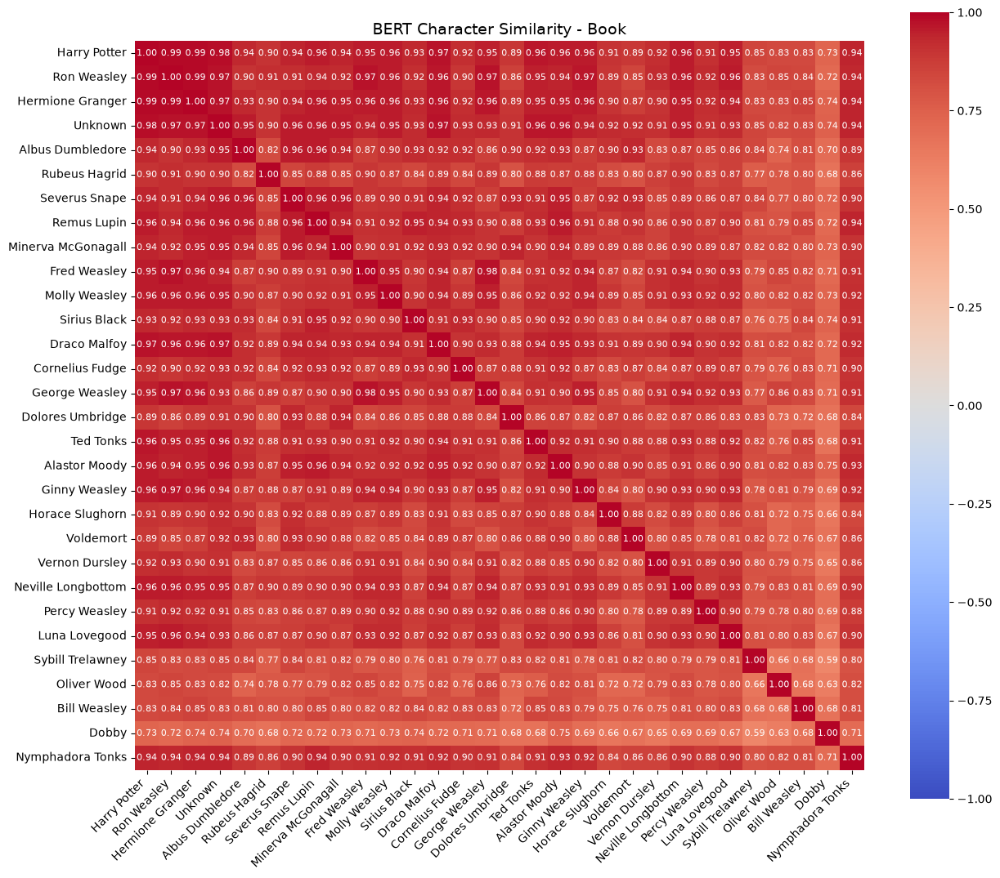


MOVIE SIMILARITIES
Mean: 0.8
Median: 0.828
Minimum: 0.386
Maximum: 0.97


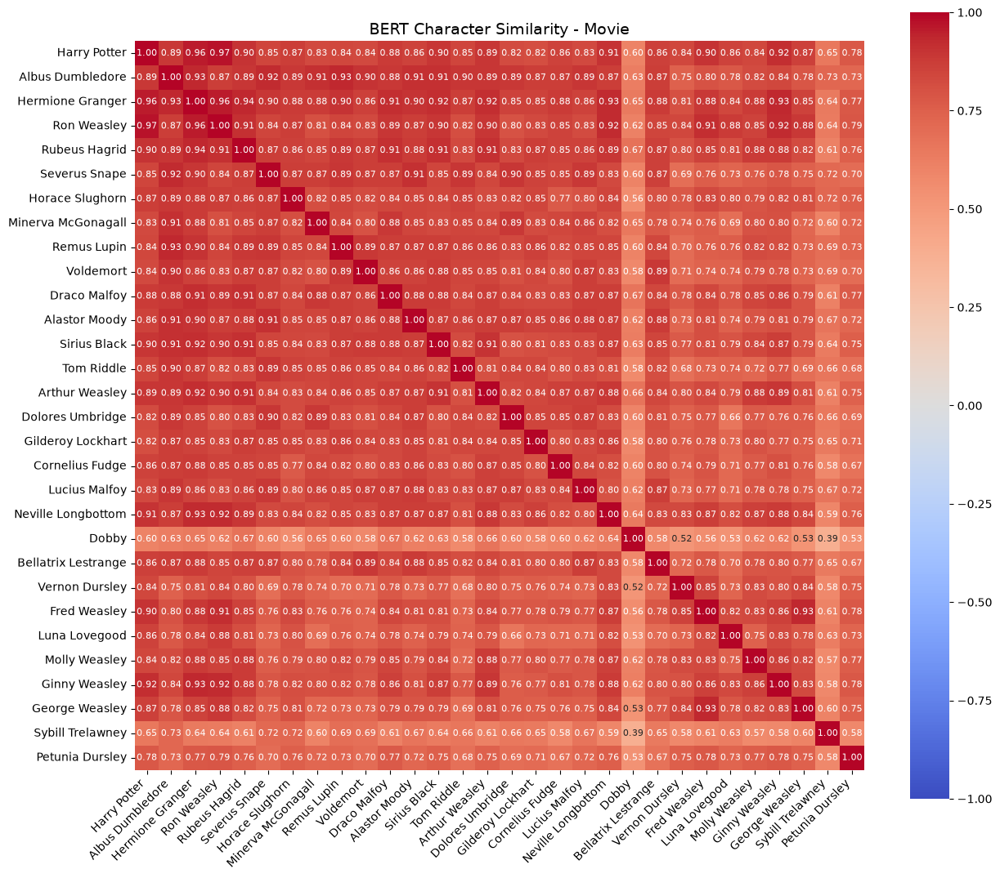

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_bert_heatmap(similarity_df, version):

    plt.figure(figsize=(13, 11))

    sns.heatmap(
        similarity_df,
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 8},
        square=True
    )

    plt.title(
        f"BERT Character Similarity - {version.capitalize()}",
        fontsize=14
    )

    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()


# Books
book_bert_similarity = get_bert_similarity("book")
plot_bert_heatmap(book_bert_similarity, "book")

# Movies
movie_bert_similarity = get_bert_similarity("movie")
plot_bert_heatmap(movie_bert_similarity, "movie")

In [ ]:
from sklearn.decomposition import PCA

# Collect top 20 characters from both versions
selected_keys = []

for version in ["book", "movie"]:

    top = get_top_characters(version, 20)

    for character in top.index:

        key = (version, character)

        if key in bert_character_embeddings:
            selected_keys.append(key)


# Create embedding matrix
X = np.vstack([
    bert_character_embeddings[key]
    for key in selected_keys
])

# Apply PCA
pca = PCA(n_components=2, random_state=42)

X_2d = pca.fit_transform(X)

print("Explained variance by PC1 and PC2:")
print(pca.explained_variance_ratio_)

print("Total explained variance:")
print(pca.explained_variance_ratio_.sum())

Explained variance by PC1 and PC2:
[0.20496641 0.11545172]
Total explained variance:
0.3204181292472252


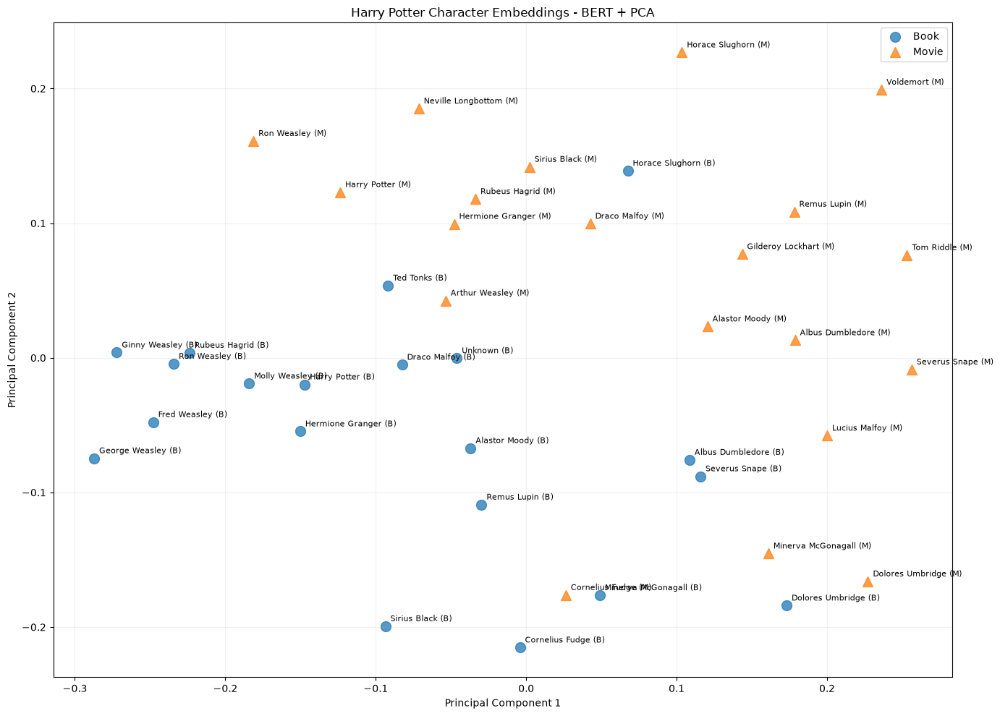

In [ ]:
plot_df = pd.DataFrame({
    "character": [key[1] for key in selected_keys],
    "version": [key[0] for key in selected_keys],
    "PC1": X_2d[:, 0],
    "PC2": X_2d[:, 1]
})

plt.figure(figsize=(14, 10))

for version, marker in [
    ("book", "o"),
    ("movie", "^")
]:

    subset = plot_df[
        plot_df["version"] == version
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=version.capitalize(),
        marker=marker,
        s=100,
        alpha=0.75
    )

    for _, row in subset.iterrows():

        plt.annotate(
            f"{row['character']} ({row['version'][0].upper()})",
            (row["PC1"], row["PC2"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

plt.title("Harry Potter Character Embeddings - BERT + PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [ ]:
# Make sure version names are consistent
df["version"] = df["version"].str.lower().replace({
    "film": "movie"
})

# Calculate dialogue word counts
df["word_count"] = (
    df["dialog"].fillna("").astype(str).str.split().str.len()
)

# Total dialogue words per movie character
movie_counts = (
    df[df["version"] == "movie"]
    .groupby("character")["word_count"]
    .sum()
    .sort_values(ascending=False)
)

# Find characters that have embeddings in BOTH versions
common_characters = [
    character
    for character in movie_counts.index
    if (
        ("movie", character) in bert_character_embeddings
        and ("book", character) in bert_character_embeddings
    )
]

# Select top 25, ranked by movie dialogue volume
selected_characters = common_characters[:30]

print("Selected characters:")
for i, character in enumerate(selected_characters, 1):
    print(i, character, movie_counts[character])

print("\nNumber of selected characters:", len(selected_characters))

Selected characters:
1 Harry Potter 13970
2 Albus Dumbledore 7653
3 Hermione Granger 7634
4 Ron Weasley 6916
5 Rubeus Hagrid 3473
6 Severus Snape 2381
7 Horace Slughorn 2194
8 Minerva McGonagall 1962
9 Remus Lupin 1902
10 Voldemort 1712
11 Draco Malfoy 1275
12 Alastor Moody 1196
13 Sirius Black 1082
14 Dolores Umbridge 958
15 Gilderoy Lockhart 887
16 Cornelius Fudge 782
17 Lucius Malfoy 770
18 Neville Longbottom 761
19 Dobby 727
20 Bellatrix Lestrange 689
21 Vernon Dursley 679
22 Fred Weasley 599
23 Luna Lovegood 553
24 Molly Weasley 543
25 Ginny Weasley 505
26 George Weasley 483
27 Sybill Trelawney 439
28 Petunia Dursley 397
29 Bartemius Crouch 354
30 Rufus Scrimgeour 339

Number of selected characters: 30


In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics.pairwise import cosine_similarity

# Create book embedding matrix
book_X = np.vstack([
    bert_character_embeddings[("book", character)]
    for character in selected_characters
])

# Create movie embedding matrix
movie_X = np.vstack([
    bert_character_embeddings[("movie", character)]
    for character in selected_characters
])

# Calculate similarities independently
book_similarity = cosine_similarity(book_X)
movie_similarity = cosine_similarity(movie_X)

# Convert to DataFrames
book_similarity_df = pd.DataFrame(
    book_similarity,
    index=selected_characters,
    columns=selected_characters
)

movie_similarity_df = pd.DataFrame(
    movie_similarity,
    index=selected_characters,
    columns=selected_characters
)

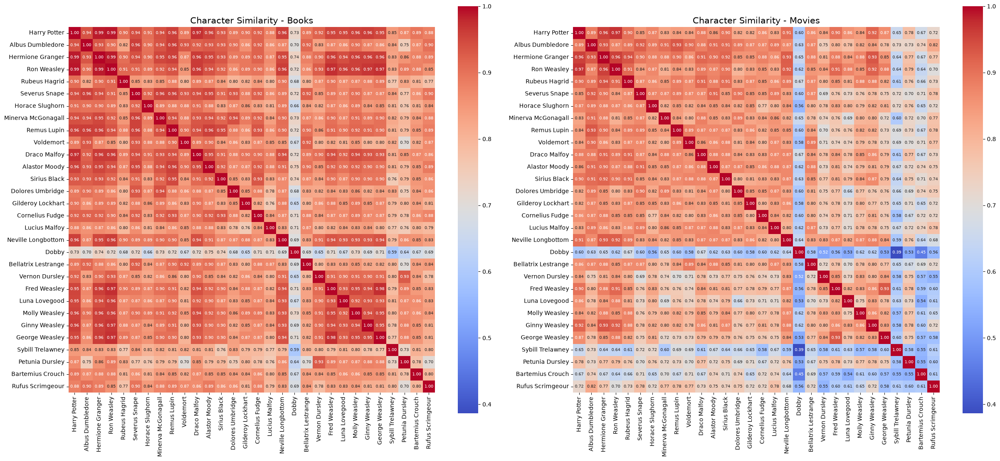

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Use the same colour range for both heatmaps
vmin = min(book_similarity.min(), movie_similarity.min())
vmax = max(book_similarity.max(), movie_similarity.max())

fig, axes = plt.subplots(1, 2, figsize=(25, 11))

# Book heatmap
sns.heatmap(
    book_similarity_df,
    ax=axes[0],
    cmap="coolwarm",
    vmin=vmin,
    vmax=vmax,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    square=True
)

axes[0].set_title("Character Similarity - Books", fontsize=15)
axes[0].tick_params(axis="x", rotation=90)
axes[0].tick_params(axis="y", rotation=0)

# Movie heatmap
sns.heatmap(
    movie_similarity_df,
    ax=axes[1],
    cmap="coolwarm",
    vmin=vmin,
    vmax=vmax,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    square=True
)

axes[1].set_title("Character Similarity - Movies", fontsize=15)
axes[1].tick_params(axis="x", rotation=90)
axes[1].tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
%pip install annoy

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from annoy import AnnoyIndex
print("Annoy installed successfully")

Annoy installed successfully


In [ ]:
import pacmap
import numpy as np
from sklearn.preprocessing import normalize

# Prepare embeddings
X_combined = np.vstack([
    book_X,
    movie_X
])

X_combined = normalize(X_combined, norm="l2")
X_combined = np.ascontiguousarray(
    X_combined, dtype=np.float32
)

# PaCMAP using Annoy instead of FAISS
reducer = pacmap.PaCMAP(
    n_components=2,
    n_neighbors=5,
    MN_ratio=0.5,
    FP_ratio=1.0,
    knn_backend="annoy",
    verbose=True,
    random_state=42
)

# Project into 2D
X_pacmap = reducer.fit_transform(
    X_combined,
    init="pca"
)

print("Result shape:", X_pacmap.shape)

Applied PCA, the dimensionality becomes 100
PaCMAP(n_neighbors=5, n_MN=2, n_FP=5, distance=euclidean, lr=1.0, n_iters=(100, 100, 250), apply_pca=True, opt_method='adam', verbose=True, intermediate=False, seed=42, knn_backend=annoy)
Finding pairs
Found nearest neighbor
Calculated sigma
Found scaled dist
Pairs sampled successfully.
((300, 2), (120, 2), (300, 2))
Initial Loss: 216.5438690185547
Iteration:   10, Loss: 188.782318
Iteration:   20, Loss: 169.967987
Iteration:   30, Loss: 163.101288
Iteration:   40, Loss: 158.148102
Iteration:   50, Loss: 154.086273
Iteration:   60, Loss: 150.134735
Iteration:   70, Loss: 145.972595
Iteration:   80, Loss: 141.428040
Iteration:   90, Loss: 136.246780
Iteration:  100, Loss: 129.844147
Iteration:  110, Loss: 169.372406
Iteration:  120, Loss: 169.034744
Iteration:  130, Loss: 168.916046
Iteration:  140, Loss: 168.877579
Iteration:  150, Loss: 168.859940
Iteration:  160, Loss: 168.859161
Iteration:  170, Loss: 168.864792
Iteration:  180, Loss: 168.

In [ ]:
import pacmap
import inspect
import sys

print("Version:", pacmap.__version__)
print("Package location:", pacmap.__file__)
print("Python:", sys.executable)

print("\nSupported parameters:")
print(inspect.signature(pacmap.PaCMAP))

Version: 0.9.1
Package location: /Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/pacmap/__init__.py
Python: /usr/local/bin/python3.11

Supported parameters:
(n_components=2, n_neighbors=10, MN_ratio=0.5, FP_ratio=2.0, pair_neighbors=None, pair_MN=None, pair_FP=None, distance='euclidean', lr=1.0, num_iters=(100, 100, 250), verbose=False, apply_pca=True, intermediate=False, intermediate_snapshots=[0, 10, 30, 60, 100, 120, 140, 170, 200, 250, 300, 350, 450], random_state=None, save_tree=False, knn_backend='faiss')


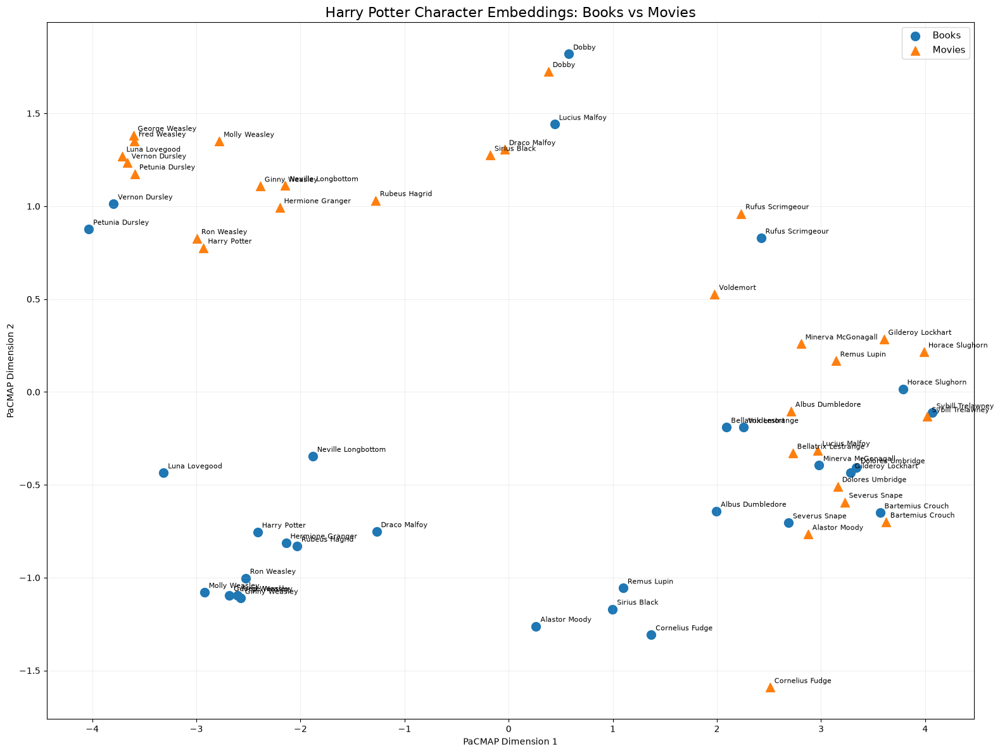

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

n = len(selected_characters)

# Separate book and movie coordinates
book_coordinates = X_pacmap[:n]
movie_coordinates = X_pacmap[n:]

# Create figure
plt.figure(figsize=(16, 12))

# Plot book embeddings
plt.scatter(
    book_coordinates[:, 0],
    book_coordinates[:, 1],
    marker="o",
    s=100,
    label="Books"
)

# Plot movie embeddings
plt.scatter(
    movie_coordinates[:, 0],
    movie_coordinates[:, 1],
    marker="^",
    s=100,
    label="Movies"
)

# Add character labels directly at their projected positions
for i, character in enumerate(selected_characters):

    # Book label
    plt.annotate(
        character,
        book_coordinates[i],
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

    # Movie label
    plt.annotate(
        character,
        movie_coordinates[i],
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.title(
    "Harry Potter Character Embeddings: Books vs Movies",
    fontsize=16
)

plt.xlabel("PaCMAP Dimension 1")
plt.ylabel("PaCMAP Dimension 2")

plt.legend(fontsize=11)
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()

Villain analysis

In [ ]:
villains = [
    "Voldemort",
    "Bellatrix Lestrange",
    "Dolores Umbridge",
    "Lucius Malfoy",
    "Bartemius Crouch"
]

ambiguous = [
    "Severus Snape",
    "Draco Malfoy",
    "Horace Slughorn",
    "Gilderoy Lockhart",
    "Cornelius Fudge",
    "Vernon Dursley",
    "Petunia Dursley",
    "Rufus Scrimgeour"
]

non_villains = [
    "Harry Potter",
    "Albus Dumbledore",
    "Hermione Granger",
    "Ron Weasley",
    "Rubeus Hagrid",
    "Minerva McGonagall",
    "Remus Lupin",
    "Alastor Moody",
    "Sirius Black",
    "Neville Longbottom",
    "Dobby",
    "Fred Weasley",
    "Luna Lovegood",
    "Molly Weasley",
    "Ginny Weasley",
    "George Weasley",
    "Sybill Trelawney"
]

# Villains first, ambiguous second, non-villains last
ordered_characters = villains + ambiguous + non_villains

# Check that all selected characters are accounted for
assert set(ordered_characters) == set(selected_characters)
assert len(ordered_characters) == len(set(ordered_characters))

print(f"Villains: {len(villains)}")
print(f"Ambiguous: {len(ambiguous)}")
print(f"Non-villains: {len(non_villains)}")
print(f"Total: {len(ordered_characters)}")

print(ordered_characters)

Villains: 5
Ambiguous: 8
Non-villains: 17
Total: 30
['Voldemort', 'Bellatrix Lestrange', 'Dolores Umbridge', 'Lucius Malfoy', 'Bartemius Crouch', 'Severus Snape', 'Draco Malfoy', 'Horace Slughorn', 'Gilderoy Lockhart', 'Cornelius Fudge', 'Vernon Dursley', 'Petunia Dursley', 'Rufus Scrimgeour', 'Harry Potter', 'Albus Dumbledore', 'Hermione Granger', 'Ron Weasley', 'Rubeus Hagrid', 'Minerva McGonagall', 'Remus Lupin', 'Alastor Moody', 'Sirius Black', 'Neville Longbottom', 'Dobby', 'Fred Weasley', 'Luna Lovegood', 'Molly Weasley', 'Ginny Weasley', 'George Weasley', 'Sybill Trelawney']


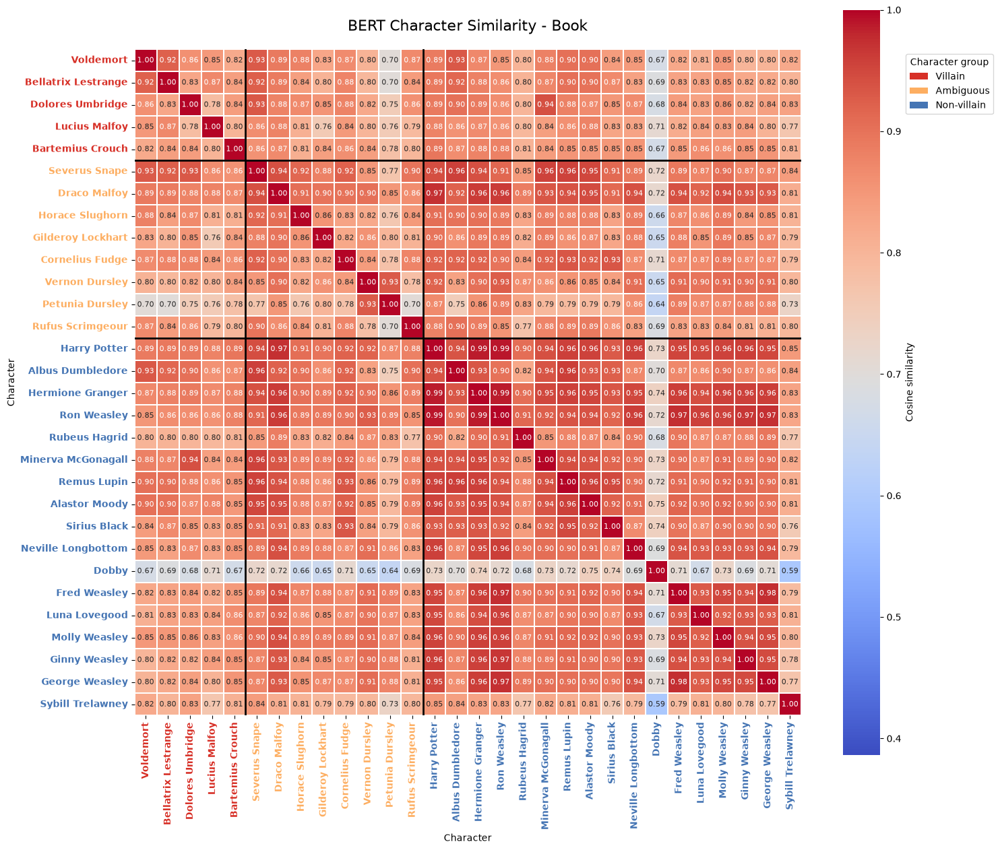

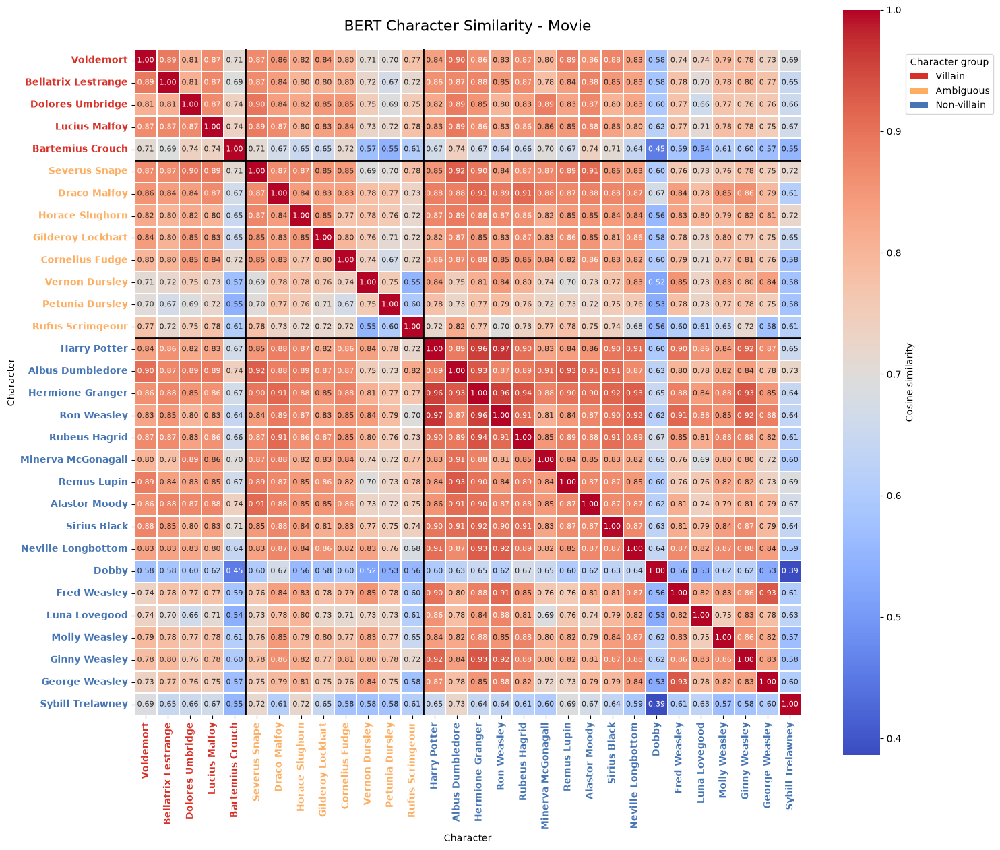

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from matplotlib.patches import Patch

# Group sizes
n_villains = len(villains)
n_ambiguous = len(ambiguous)
n_non_villains = len(non_villains)

# Colors for character groups
group_colors = {
    "Villain": "#d73027",
    "Ambiguous": "#fdae61",
    "Non-villain": "#4575b4"
}

# Color for each character
character_colors = (
    [group_colors["Villain"]] * n_villains
    + [group_colors["Ambiguous"]] * n_ambiguous
    + [group_colors["Non-villain"]] * n_non_villains
)

def plot_grouped_heatmap(similarity_df, version):

    # Reorder rows and columns
    similarity_df = similarity_df.loc[
        ordered_characters,
        ordered_characters
    ]

    fig, ax = plt.subplots(figsize=(15, 13))

    # Use the same colour range for both heatmaps
    vmin = min(book_similarity.min(), movie_similarity.min())
    vmax = max(book_similarity.max(), movie_similarity.max())

    sns.heatmap(
        similarity_df,
        cmap="coolwarm",
        vmin=vmin,
        vmax=vmax,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 8},
        square=True,
        linewidths=0.3,
        ax=ax,
        cbar_kws={"label": "Cosine similarity"}
    )

    # Color tick labels according to character group
    for i, label in enumerate(ax.get_xticklabels()):
        label.set_color(character_colors[i])
        label.set_fontweight("bold")

    for i, label in enumerate(ax.get_yticklabels()):
        label.set_color(character_colors[i])
        label.set_fontweight("bold")

    # Add separating lines between groups
    boundaries = [
        n_villains,
        n_villains + n_ambiguous
    ]

    for boundary in boundaries:
        ax.axhline(boundary, color="black", linewidth=2)
        ax.axvline(boundary, color="black", linewidth=2)

    ax.set_title(
        f"BERT Character Similarity - {version.capitalize()}",
        fontsize=16,
        pad=20
    )

    ax.set_xlabel("Character")
    ax.set_ylabel("Character")

    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)

    # Legend
    legend_elements = [
        Patch(facecolor=group_colors["Villain"], label="Villain"),
        Patch(facecolor=group_colors["Ambiguous"], label="Ambiguous"),
        Patch(facecolor=group_colors["Non-villain"], label="Non-villain")
    ]

    ax.legend(
        handles=legend_elements,
        loc="upper left",
        bbox_to_anchor=(1.15, 1),
        title="Character group"
    )

    plt.tight_layout()
    plt.show()


# Plot books
plot_grouped_heatmap(book_similarity_df, "book")

# Plot movies
plot_grouped_heatmap(movie_similarity_df, "movie")

In [ ]:
def compare_character_groups(similarity_df):

    def get_group_similarity(group1, group2, exclude_diagonal=False):

        values = similarity_df.loc[
            group1, group2
        ].to_numpy()

        if exclude_diagonal:
            mask = ~np.eye(len(group1), dtype=bool)
            values = values[mask]

        return values.mean()

    villain_villain = get_group_similarity(
        villains, villains, exclude_diagonal=True
    )

    nonvillain_nonvillain = get_group_similarity(
        non_villains, non_villains, exclude_diagonal=True
    )

    villain_nonvillain = get_group_similarity(
        villains, non_villains
    )

    return pd.Series({
        "Villain-Villain": villain_villain,
        "Non-villain-Non-villain": nonvillain_nonvillain,
        "Villain-Non-villain": villain_nonvillain
    })


results = pd.DataFrame({
    "Books": compare_character_groups(book_similarity_df),
    "Movies": compare_character_groups(movie_similarity_df)
})

print(results.round(3))

                         Books  Movies
Villain-Villain          0.841   0.799
Non-villain-Non-villain  0.884   0.800
Villain-Non-villain      0.842   0.763


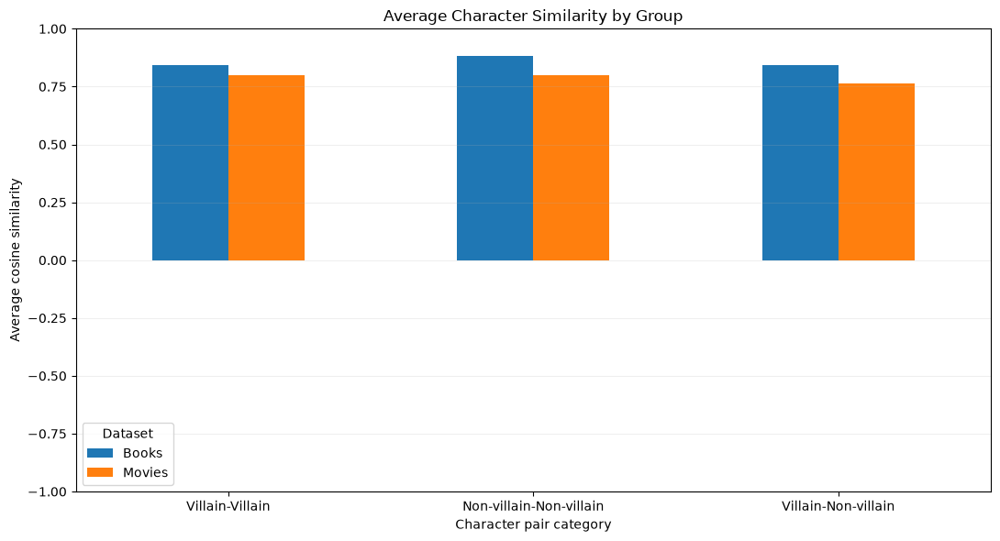

In [ ]:
results.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(-1, 1),
    rot=0
)

plt.title("Average Character Similarity by Group")
plt.ylabel("Average cosine similarity")
plt.xlabel("Character pair category")
plt.legend(title="Dataset")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

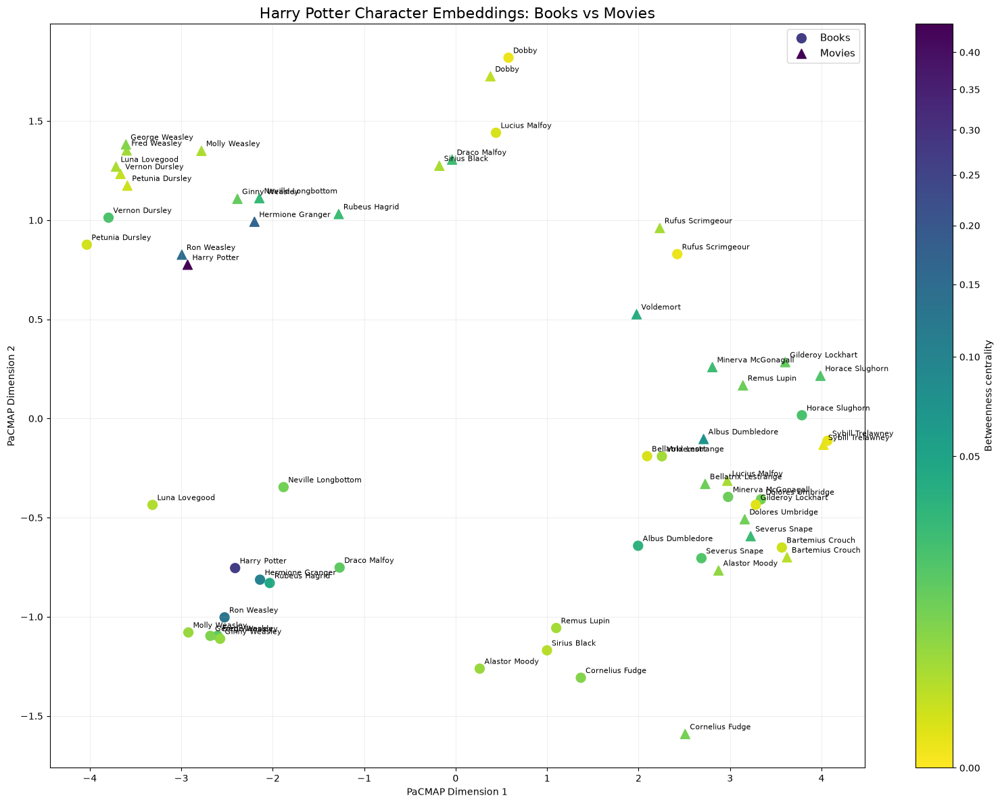

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import PowerNorm
from matplotlib.cm import ScalarMappable

# Build one dialogue interaction graph per version. Consecutive attributed
# speakers in each source file are connected, matching the dialogue network rule.
def dialogue_graph(version):
    graph = nx.Graph()
    version_df = df[df["version"] == version]
    graph.add_nodes_from(version_df["character"].dropna().unique())

    for _, source_df in version_df.groupby("source_file", sort=False):
        speakers = source_df["character"].dropna().tolist()
        for first, second in zip(speakers, speakers[1:]):
            if first != second:
                graph.add_edge(first, second)

    return graph

book_graph = dialogue_graph("book")
movie_graph = dialogue_graph("movie")
book_betweenness = nx.betweenness_centrality(book_graph, normalized=True)
movie_betweenness = nx.betweenness_centrality(movie_graph, normalized=True)

n = len(selected_characters)
book_coordinates = X_pacmap[:n]
movie_coordinates = X_pacmap[n:]
book_scores = np.array([book_betweenness.get(character, 0.0) for character in selected_characters])
movie_scores = np.array([movie_betweenness.get(character, 0.0) for character in selected_characters])

# A shared scale makes book and movie betweenness directly comparable.
vmax = max(book_scores.max(initial=0), movie_scores.max(initial=0))
color_norm = PowerNorm(gamma=0.4, vmin=0, vmax=vmax if vmax > 0 else 1)
cmap = plt.get_cmap("viridis_r")

plt.figure(figsize=(16, 12))
plt.scatter(
    book_coordinates[:, 0], book_coordinates[:, 1],
    c=book_scores, cmap=cmap, norm=color_norm,
    marker="o", s=100, label="Books"
)
plt.scatter(
    movie_coordinates[:, 0], movie_coordinates[:, 1],
    c=movie_scores, cmap=cmap, norm=color_norm,
    marker="^", s=100, label="Movies"
)

for i, character in enumerate(selected_characters):
    plt.annotate(character, book_coordinates[i], xytext=(5, 5), textcoords="offset points", fontsize=8)
    plt.annotate(character, movie_coordinates[i], xytext=(5, 5), textcoords="offset points", fontsize=8)

plt.title("Harry Potter Character Embeddings: Books vs Movies", fontsize=16)
plt.xlabel("PaCMAP Dimension 1")
plt.ylabel("PaCMAP Dimension 2")
plt.legend(fontsize=11)
plt.grid(alpha=0.2)
colorbar = plt.colorbar(ScalarMappable(norm=color_norm, cmap=cmap), ax=plt.gca())
colorbar.set_label("Betweenness centrality")
plt.tight_layout()
plt.show()


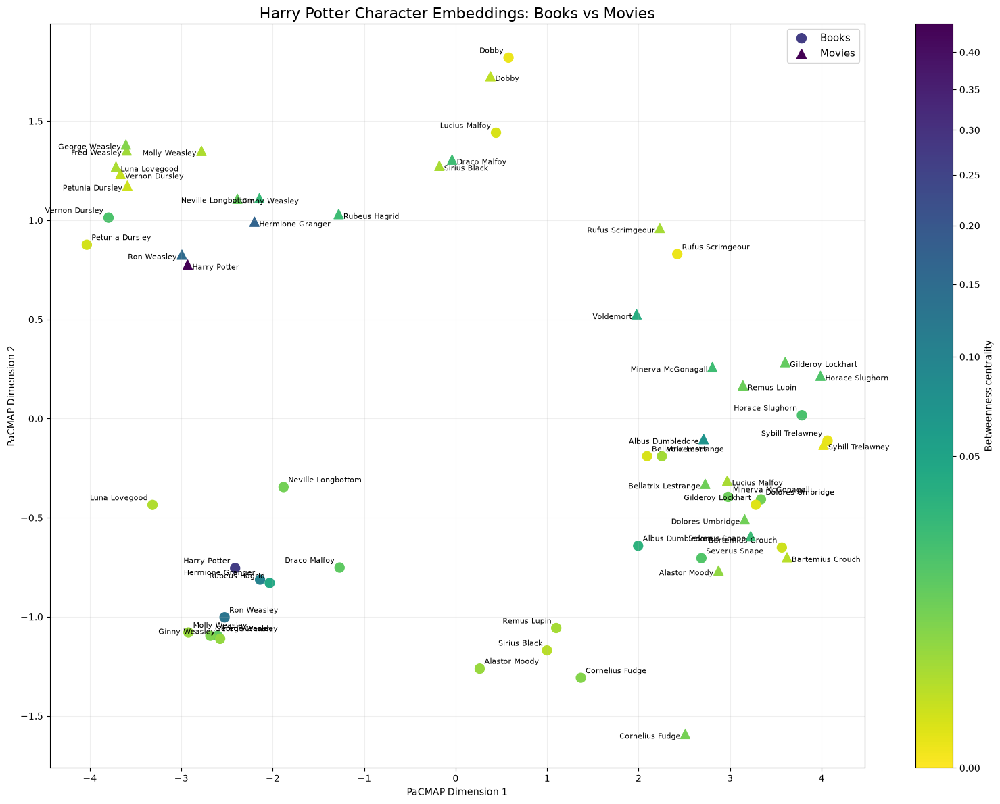

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import PowerNorm
from matplotlib.cm import ScalarMappable

# Build one dialogue interaction graph per version. Consecutive attributed
# speakers in each source file are connected, matching the dialogue network rule.
def dialogue_graph(version):
    graph = nx.Graph()
    version_df = df[df["version"] == version]
    graph.add_nodes_from(version_df["character"].dropna().unique())

    for _, source_df in version_df.groupby("source_file", sort=False):
        speakers = source_df["character"].dropna().tolist()
        for first, second in zip(speakers, speakers[1:]):
            if first != second:
                graph.add_edge(first, second)

    return graph

book_graph = dialogue_graph("book")
movie_graph = dialogue_graph("movie")
book_betweenness = nx.betweenness_centrality(book_graph, normalized=True)
movie_betweenness = nx.betweenness_centrality(movie_graph, normalized=True)

n = len(selected_characters)
book_coordinates = X_pacmap[:n]
movie_coordinates = X_pacmap[n:]
book_scores = np.array([book_betweenness.get(character, 0.0) for character in selected_characters])
movie_scores = np.array([movie_betweenness.get(character, 0.0) for character in selected_characters])

# A shared scale makes book and movie betweenness directly comparable.
vmax = max(book_scores.max(initial=0), movie_scores.max(initial=0))
color_norm = PowerNorm(gamma=0.4, vmin=0, vmax=vmax if vmax > 0 else 1)
cmap = plt.get_cmap("viridis_r")

plt.figure(figsize=(16, 12))
plt.scatter(
    book_coordinates[:, 0], book_coordinates[:, 1],
    c=book_scores, cmap=cmap, norm=color_norm,
    marker="o", s=100, label="Books"
)
plt.scatter(
    movie_coordinates[:, 0], movie_coordinates[:, 1],
    c=movie_scores, cmap=cmap, norm=color_norm,
    marker="^", s=100, label="Movies"
)

for i, character in enumerate(selected_characters):
    # Alternate label sides to reduce collisions between nearby points.
    book_offset = (-5, 5) if i % 2 == 0 else (5, 5)
    book_alignment = "right" if i % 2 == 0 else "left"
    movie_offset = (5, -5) if i % 2 == 0 else (-5, -5)
    movie_alignment = "left" if i % 2 == 0 else "right"
    plt.annotate(character, book_coordinates[i], xytext=book_offset, textcoords="offset points", ha=book_alignment, fontsize=8)
    plt.annotate(character, movie_coordinates[i], xytext=movie_offset, textcoords="offset points", ha=movie_alignment, fontsize=8)

plt.title("Harry Potter Character Embeddings: Books vs Movies", fontsize=16)
plt.xlabel("PaCMAP Dimension 1")
plt.ylabel("PaCMAP Dimension 2")
plt.legend(fontsize=11)
plt.grid(alpha=0.2)
colorbar = plt.colorbar(ScalarMappable(norm=color_norm, cmap=cmap), ax=plt.gca())
colorbar.set_label("Betweenness centrality")
plt.tight_layout()
plt.show()


In [ ]:
# Build the dialogue interaction network using the next-turn edge rule from code/big_graphs.py.
import networkx as nx

community_aliases = {"Tom Riddle":"Voldemort", "Garrick Ollivander":"Ollivander", "Poppy Pomfrey":"Madam Pomfrey", "Rolanda Hooch":"Madam Hooch", "Stanley Shunpike":"Stan Shunpike", "Collin Creevey":"Colin Creevey", "Ernest Macmillan":"Ernie Macmillan"}
non_specific_movie_labels = {"all", "announcer", "basilisk", "boy", "boy 2", "centaur", "class", "crowd", "death eater", "diary", "gang thug", "ghost", "ghosts", "girl", "goblin", "gryffindors", "guard", "howler", "maid", "man", "man in a painting", "merpeople", "other", "patronus", "pixie", "professors", "shrunken head", "skinny kid", "snake", "snatcher", "station guard", "student", "students", "teacher", "teachers", "random guard", "random teacher", "professor", "trolley witch", "waiter", "waitress", "whomping willow", "witch", "wizard", "woman", "old man"}

def canonical_community_name(name):
    name = str(name).strip()
    return community_aliases.get(name, name)

dialogue_networks = {}
for version in ("book", "movie"):
    graph = nx.Graph()
    version_rows = df[df["version"] == version]
    for _, source_chapter in version_rows.groupby(["source_file", "chapter"], sort=False):
        speakers = []
        for raw_name in source_chapter["character"].dropna():
            name = canonical_community_name(raw_name)
            if not name or name.casefold() == "unknown":
                continue
            if version == "movie" and name.casefold() in non_specific_movie_labels:
                continue
            speakers.append(name)
            graph.add_node(name)
        for first, second in zip(speakers, speakers[1:]):
            if first != second:
                graph.add_edge(first, second)
    dialogue_networks[version] = graph

print({version: (graph.number_of_nodes(), graph.number_of_edges()) for version, graph in dialogue_networks.items()})


{'book': (114, 769), 'movie': (127, 597)}


In [ ]:
# Detect Louvain communities independently for books and movies, matching the seed and ordering in code/big_graphs.py.
def ordered_communities(graph):
    if graph.number_of_nodes() == 0:
        return []
    if graph.number_of_edges() == 0:
        groups = [{node} for node in graph]
    else:
        groups = list(nx.community.louvain_communities(graph, weight=None, seed=42))
    return sorted(groups, key=lambda group: (-len(group), min(group, key=str.casefold).casefold()))

community_groups = {version: ordered_communities(graph) for version, graph in dialogue_networks.items()}
community_by_character = {
    version: {character: community_id for community_id, group in enumerate(groups) for character in group}
    for version, groups in community_groups.items()
}
for version, groups in community_groups.items():
    print(f"{version.capitalize()}: {len(groups)} communities")


Book: 5 communities
Movie: 7 communities


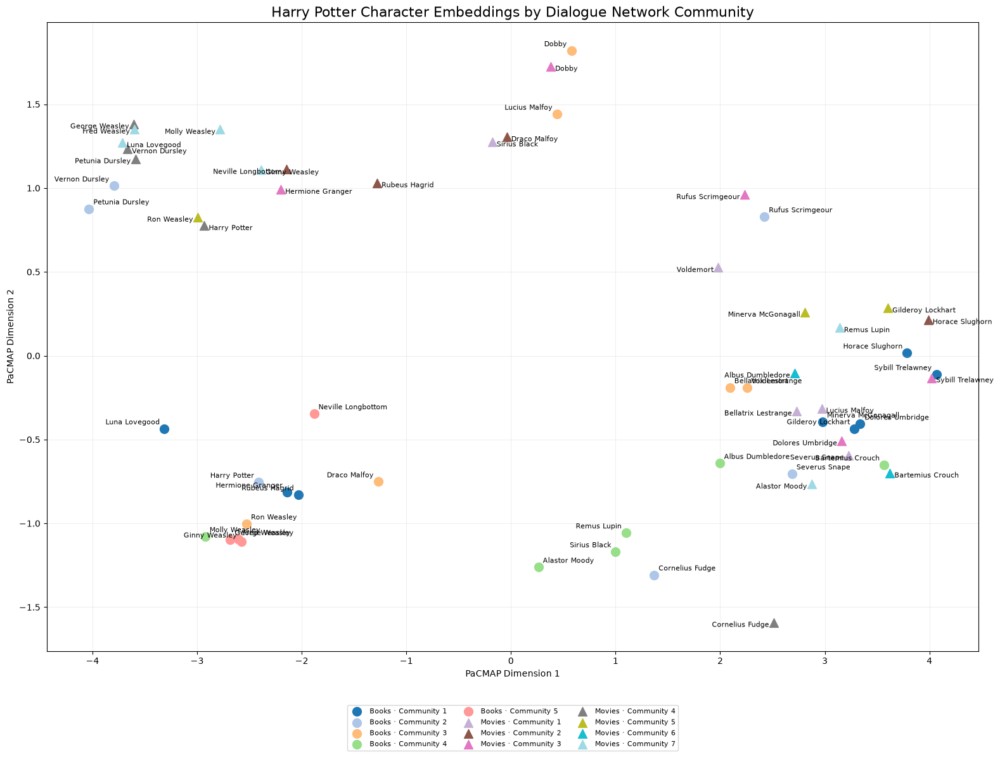

In [ ]:
# Plot BERT PaCMAP coordinates, colored by the character's community in each dialogue network.
import matplotlib.pyplot as plt

n = len(selected_characters)
book_coordinates = X_pacmap[:n]
movie_coordinates = X_pacmap[n:]
book_community_ids = [community_by_character["book"].get(canonical_community_name(character)) for character in selected_characters]
movie_community_ids = [community_by_character["movie"].get(canonical_community_name(character)) for character in selected_characters]
community_keys = sorted(
    {("Books", value) for value in book_community_ids if value is not None}
    | {("Movies", value) for value in movie_community_ids if value is not None}
)
community_cmap = plt.get_cmap("tab20", max(1, len(community_keys)))
community_colors = {key: community_cmap(i) for i, key in enumerate(community_keys)}

fig, ax = plt.subplots(figsize=(16, 12))
for medium, coordinates, ids, marker in (
    ("Books", book_coordinates, book_community_ids, "o"),
    ("Movies", movie_coordinates, movie_community_ids, "^"),
):
    for community_id in sorted({value for value in ids if value is not None}):
        indices = [i for i, value in enumerate(ids) if value == community_id]
        ax.scatter(coordinates[indices, 0], coordinates[indices, 1],
                   color=[community_colors[(medium, community_id)]], marker=marker, s=100,
                   label=f"{medium} · Community {community_id + 1}")
    missing = [i for i, value in enumerate(ids) if value is None]
    if missing:
        ax.scatter(coordinates[missing, 0], coordinates[missing, 1], color="lightgray",
                   marker=marker, s=100, label=f"{medium} · no community")

for i, character in enumerate(selected_characters):
    book_offset = (-5, 5) if i % 2 == 0 else (5, 5)
    book_ha = "right" if i % 2 == 0 else "left"
    movie_offset = (5, -5) if i % 2 == 0 else (-5, -5)
    movie_ha = "left" if i % 2 == 0 else "right"
    ax.annotate(character, book_coordinates[i], xytext=book_offset, textcoords="offset points", ha=book_ha, fontsize=8)
    ax.annotate(character, movie_coordinates[i], xytext=movie_offset, textcoords="offset points", ha=movie_ha, fontsize=8)

ax.set_title("Harry Potter Character Embeddings by Dialogue Network Community", fontsize=16)
ax.set_xlabel("PaCMAP Dimension 1")
ax.set_ylabel("PaCMAP Dimension 2")
ax.grid(alpha=0.2)
ax.legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08))
fig.tight_layout()
plt.show()


### 3D BERT embeddings by dialogue network community


In [ ]:
# Compute a fresh three-dimensional PaCMAP projection from the same selected BERT embeddings.
reducer_3d = pacmap.PaCMAP(
    n_components=3,
    n_neighbors=5,
    MN_ratio=0.5,
    FP_ratio=1.0,
    knn_backend="annoy",
    verbose=True,
    random_state=42
)
X_pacmap_3d = reducer_3d.fit_transform(X_combined, init="pca")
print("3D PaCMAP result shape:", X_pacmap_3d.shape)


Note: `n_components != 2` have not been thoroughly tested.


Applied PCA, the dimensionality becomes 100
PaCMAP(n_neighbors=5, n_MN=2, n_FP=5, distance=euclidean, lr=1.0, n_iters=(100, 100, 250), apply_pca=True, opt_method='adam', verbose=True, intermediate=False, seed=42, knn_backend=annoy)
Finding pairs
Found nearest neighbor
Calculated sigma
Found scaled dist
Pairs sampled successfully.
((300, 2), (120, 2), (300, 2))
Initial Loss: 216.54373168945312
Iteration:   10, Loss: 195.372589
Iteration:   20, Loss: 171.402588
Iteration:   30, Loss: 163.076447
Iteration:   40, Loss: 158.215744
Iteration:   50, Loss: 153.713196
Iteration:   60, Loss: 149.763107
Iteration:   70, Loss: 145.597534
Iteration:   80, Loss: 141.100464
Iteration:   90, Loss: 136.009460
Iteration:  100, Loss: 129.854065
Iteration:  110, Loss: 169.334869
Iteration:  120, Loss: 169.030441
Iteration:  130, Loss: 168.908401
Iteration:  140, Loss: 168.867310
Iteration:  150, Loss: 168.853195
Iteration:  160, Loss: 168.846893
Iteration:  170, Loss: 168.842957
Iteration:  180, Loss: 168

### Stopword-removed character embeddings


In [ ]:
# Create a separate set of BERT character embeddings after removing English stopwords.
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from numpy.linalg import norm

english_stopwords = set(ENGLISH_STOP_WORDS)
def remove_english_stopwords(text):
    tokens = re.findall(r"[A-Za-z]+(?:['’][A-Za-z]+)?", str(text))
    return " ".join(token for token in tokens if token.lower() not in english_stopwords)

bert_character_embeddings_no_stopwords = {}
character_chunk_counts_no_stopwords = {}

for key, dialogues in character_dialogues.items():
    cleaned_dialogues = [remove_english_stopwords(dialogue) for dialogue in dialogues]
    cleaned_dialogues = [dialogue for dialogue in cleaned_dialogues if dialogue.strip()]

    passages = []
    for dialogue in cleaned_dialogues:
        passages.extend(split_long_utterance(dialogue))
    if not passages:
        continue

    passage_embeddings = bert_model.encode(
        passages,
        batch_size=32,
        show_progress_bar=False,
        convert_to_numpy=True,
        normalize_embeddings=True
    )
    weights = np.array([
        len(tokenizer.encode(passage, add_special_tokens=False))
        for passage in passages
    ], dtype=float)
    weights = np.maximum(weights, 1)
    character_embedding = np.average(passage_embeddings, axis=0, weights=weights)
    embedding_norm = norm(character_embedding)
    if embedding_norm > 0:
        character_embedding /= embedding_norm

    bert_character_embeddings_no_stopwords[key] = character_embedding
    character_chunk_counts_no_stopwords[key] = len(passages)

print("Number of stopword-removed embeddings:", len(bert_character_embeddings_no_stopwords))


Number of stopword-removed embeddings: 284


### Cosine similarity matrices


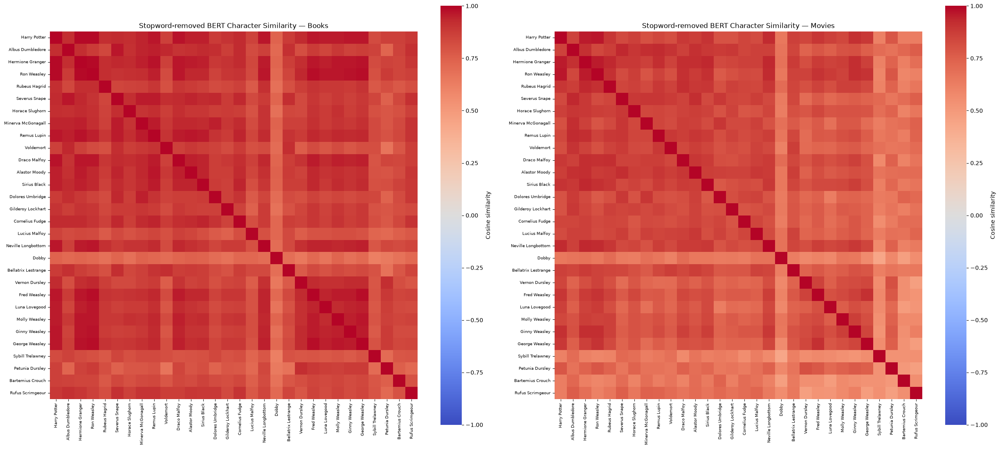

In [ ]:
# Calculate cosine similarities from the new stopword-removed embeddings.
from sklearn.metrics.pairwise import cosine_similarity

stopword_book_X = np.vstack([
    bert_character_embeddings_no_stopwords[("book", character)]
    for character in selected_characters
])
stopword_movie_X = np.vstack([
    bert_character_embeddings_no_stopwords[("movie", character)]
    for character in selected_characters
])

stopword_book_similarity = cosine_similarity(stopword_book_X)
stopword_movie_similarity = cosine_similarity(stopword_movie_X)
stopword_book_similarity_df = pd.DataFrame(
    stopword_book_similarity, index=selected_characters, columns=selected_characters
)
stopword_movie_similarity_df = pd.DataFrame(
    stopword_movie_similarity, index=selected_characters, columns=selected_characters
)

import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(25, 11))
for ax, similarity_df, title in (
    (axes[0], stopword_book_similarity_df, "Books"),
    (axes[1], stopword_movie_similarity_df, "Movies"),
):
    sns.heatmap(
        similarity_df, ax=ax, cmap="coolwarm", vmin=-1, vmax=1, center=0,
        square=True, xticklabels=True, yticklabels=True,
        cbar_kws={"label": "Cosine similarity"}
    )
    ax.set_title(f"Stopword-removed BERT Character Similarity — {title}")
    ax.tick_params(axis="x", rotation=90, labelsize=7)
    ax.tick_params(axis="y", rotation=0, labelsize=7)

fig.tight_layout()
plt.show()


### PaCMAP projection of stopword-removed embeddings


In [ ]:
# Project the new book and movie embeddings together into two PaCMAP dimensions.
import pacmap
from sklearn.preprocessing import normalize

X_stopwords_combined = np.vstack([stopword_book_X, stopword_movie_X])
X_stopwords_combined = normalize(X_stopwords_combined, norm="l2")
X_stopwords_combined = np.ascontiguousarray(X_stopwords_combined, dtype=np.float32)

reducer_stopwords = pacmap.PaCMAP(
    n_components=2,
    n_neighbors=5,
    MN_ratio=0.5,
    FP_ratio=1.0,
    knn_backend="annoy",
    verbose=True,
    random_state=42
)
X_pacmap_stopwords = reducer_stopwords.fit_transform(X_stopwords_combined, init="pca")
print("Stopword-removed PaCMAP result shape:", X_pacmap_stopwords.shape)


Applied PCA, the dimensionality becomes 100
PaCMAP(n_neighbors=5, n_MN=2, n_FP=5, distance=euclidean, lr=1.0, n_iters=(100, 100, 250), apply_pca=True, opt_method='adam', verbose=True, intermediate=False, seed=42, knn_backend=annoy)
Finding pairs
Found nearest neighbor
Calculated sigma
Found scaled dist
Pairs sampled successfully.
((300, 2), (120, 2), (300, 2))
Initial Loss: 216.54373168945312
Iteration:   10, Loss: 183.099274
Iteration:   20, Loss: 167.681854
Iteration:   30, Loss: 160.489777
Iteration:   40, Loss: 155.903244
Iteration:   50, Loss: 151.769440
Iteration:   60, Loss: 147.726990
Iteration:   70, Loss: 143.433990
Iteration:   80, Loss: 138.700562
Iteration:   90, Loss: 133.265167
Iteration:  100, Loss: 126.633629
Iteration:  110, Loss: 164.907394
Iteration:  120, Loss: 164.491745
Iteration:  130, Loss: 164.376816
Iteration:  140, Loss: 164.337112
Iteration:  150, Loss: 164.323090
Iteration:  160, Loss: 164.323196
Iteration:  170, Loss: 164.330154
Iteration:  180, Loss: 164

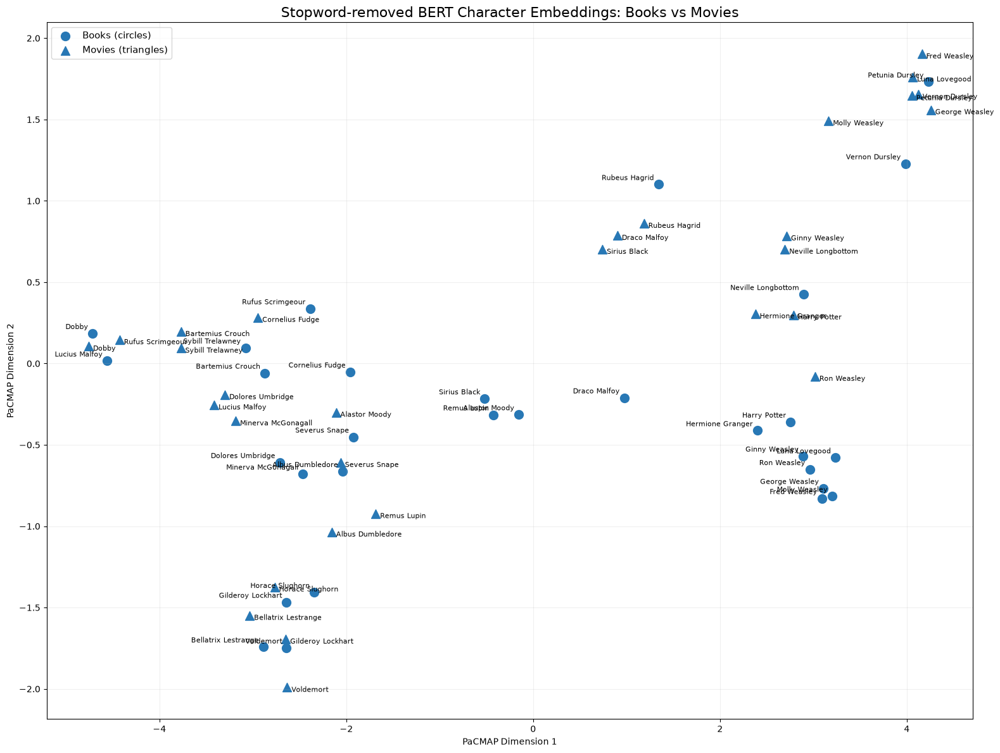

In [ ]:
# Use one color for both media; circles identify books and triangles identify movies.
import matplotlib.pyplot as plt

n = len(selected_characters)
stopword_book_coordinates = X_pacmap_stopwords[:n]
stopword_movie_coordinates = X_pacmap_stopwords[n:]
point_color = "#2878B5"

plt.figure(figsize=(16, 12))
plt.scatter(
    stopword_book_coordinates[:, 0], stopword_book_coordinates[:, 1],
    marker="o", s=100, color=point_color, label="Books (circles)"
)
plt.scatter(
    stopword_movie_coordinates[:, 0], stopword_movie_coordinates[:, 1],
    marker="^", s=100, color=point_color, label="Movies (triangles)"
)
for i, character in enumerate(selected_characters):
    plt.annotate(character, stopword_book_coordinates[i], xytext=(-5, 5),
                 textcoords="offset points", ha="right", fontsize=8)
    plt.annotate(character, stopword_movie_coordinates[i], xytext=(5, -5),
                 textcoords="offset points", ha="left", fontsize=8)

plt.title("Stopword-removed BERT Character Embeddings: Books vs Movies", fontsize=16)
plt.xlabel("PaCMAP Dimension 1")
plt.ylabel("PaCMAP Dimension 2")
plt.legend(fontsize=11)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


With stopwords

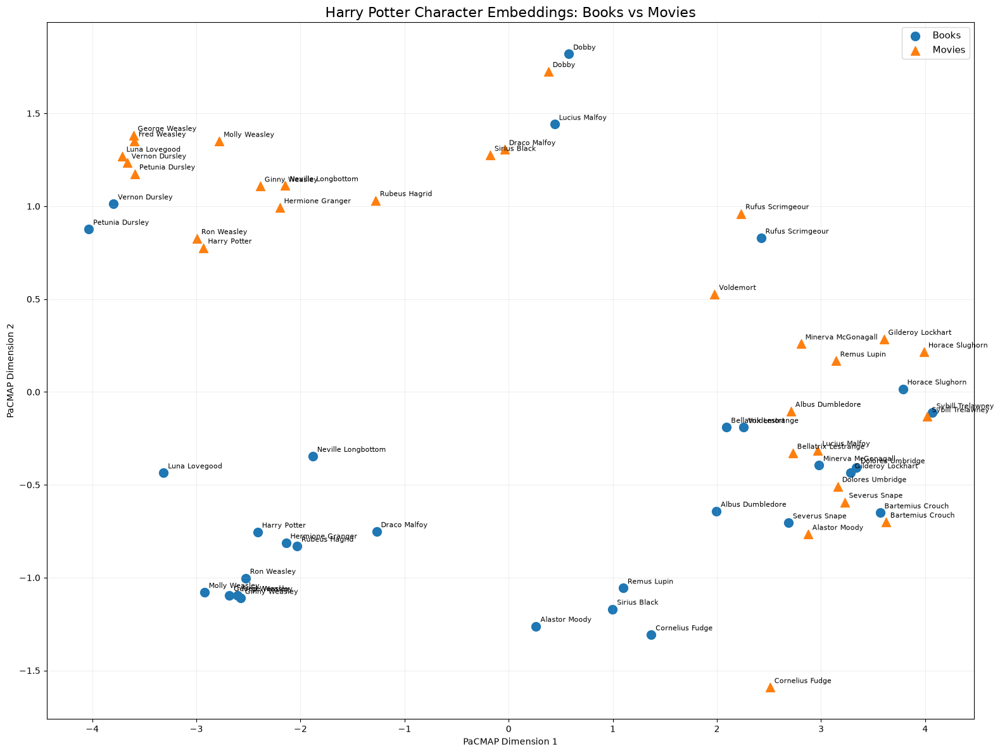

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

n = len(selected_characters)

# Separate book and movie coordinates
book_coordinates = X_pacmap[:n]
movie_coordinates = X_pacmap[n:]

# Create figure
plt.figure(figsize=(16, 12))

# Plot book embeddings
plt.scatter(
    book_coordinates[:, 0],
    book_coordinates[:, 1],
    marker="o",
    s=100,
    label="Books"
)

# Plot movie embeddings
plt.scatter(
    movie_coordinates[:, 0],
    movie_coordinates[:, 1],
    marker="^",
    s=100,
    label="Movies"
)

# Add character labels directly at their projected positions
for i, character in enumerate(selected_characters):

    # Book label
    plt.annotate(
        character,
        book_coordinates[i],
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

    # Movie label
    plt.annotate(
        character,
        movie_coordinates[i],
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.title(
    "Harry Potter Character Embeddings: Books vs Movies",
    fontsize=16
)

plt.xlabel("PaCMAP Dimension 1")
plt.ylabel("PaCMAP Dimension 2")

plt.legend(fontsize=11)
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()

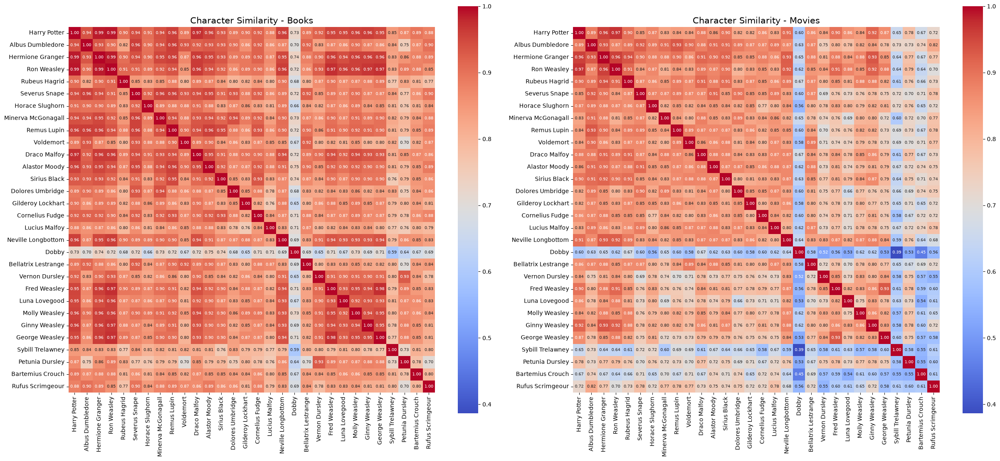

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Similarity matrices from the original embeddings, which retain stopwords.
vmin = min(book_similarity.min(), movie_similarity.min())
vmax = max(book_similarity.max(), movie_similarity.max())

fig, axes = plt.subplots(1, 2, figsize=(25, 11))

# Book heatmap
sns.heatmap(
    book_similarity_df,
    ax=axes[0],
    cmap="coolwarm",
    vmin=vmin,
    vmax=vmax,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    square=True
)
axes[0].set_title("Character Similarity - Books", fontsize=15)
axes[0].tick_params(axis="x", rotation=90)
axes[0].tick_params(axis="y", rotation=0)

# Movie heatmap
sns.heatmap(
    movie_similarity_df,
    ax=axes[1],
    cmap="coolwarm",
    vmin=vmin,
    vmax=vmax,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    square=True
)
axes[1].set_title("Character Similarity - Movies", fontsize=15)
axes[1].tick_params(axis="x", rotation=90)
axes[1].tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()


### BERT cosine similarity grouped by character role


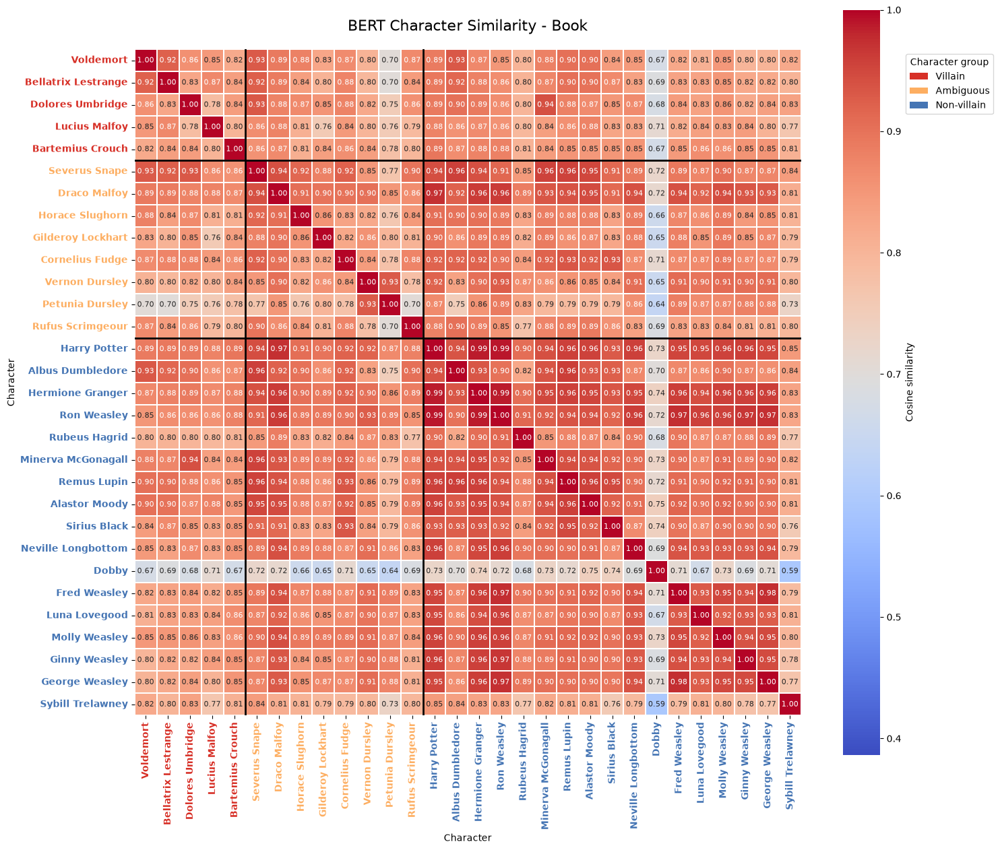

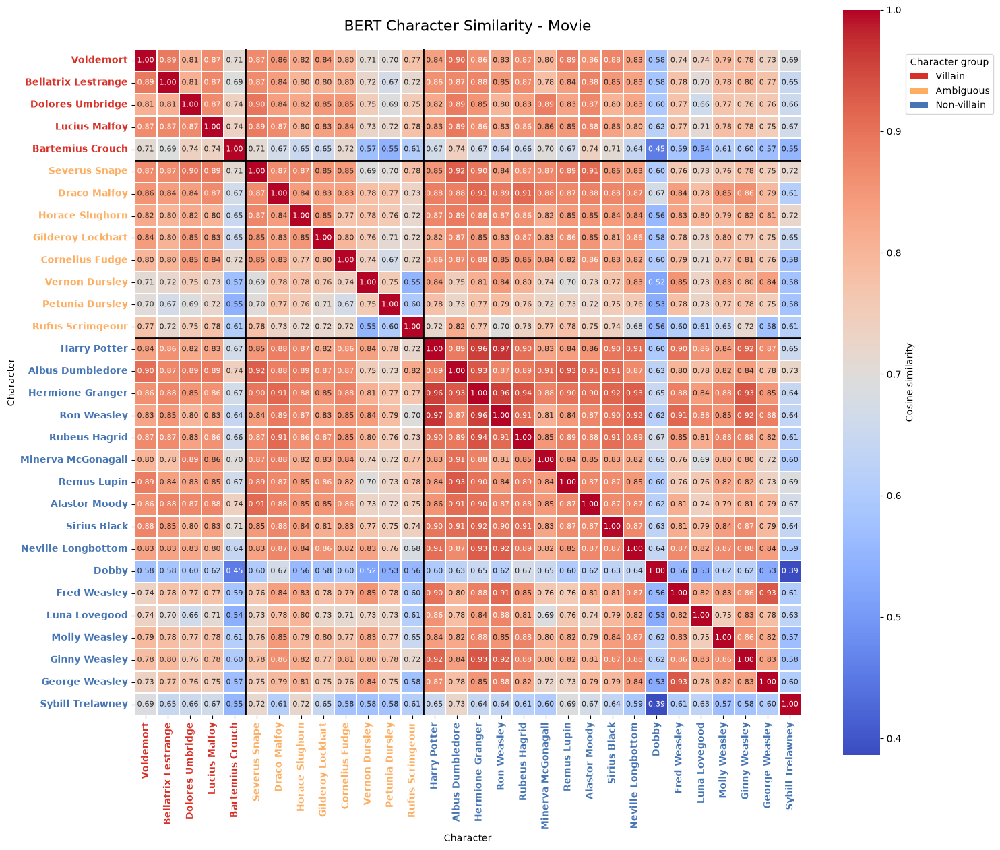

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from matplotlib.patches import Patch

# Group sizes
n_villains = len(villains)
n_ambiguous = len(ambiguous)
n_non_villains = len(non_villains)

# Colors for character groups
group_colors = {
    "Villain": "#d73027",
    "Ambiguous": "#fdae61",
    "Non-villain": "#4575b4"
}

# Color for each character
character_colors = (
    [group_colors["Villain"]] * n_villains
    + [group_colors["Ambiguous"]] * n_ambiguous
    + [group_colors["Non-villain"]] * n_non_villains
)

def plot_grouped_heatmap(similarity_df, version):

    # Reorder rows and columns
    similarity_df = similarity_df.loc[
        ordered_characters,
        ordered_characters
    ]

    fig, ax = plt.subplots(figsize=(15, 13))

    # Use the same colour range for both heatmaps
    vmin = min(book_similarity.min(), movie_similarity.min())
    vmax = max(book_similarity.max(), movie_similarity.max())

    sns.heatmap(
        similarity_df,
        cmap="coolwarm",
        vmin=vmin,
        vmax=vmax,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 8},
        square=True,
        linewidths=0.3,
        ax=ax,
        cbar_kws={"label": "Cosine similarity"}
    )

    # Color tick labels according to character group
    for i, label in enumerate(ax.get_xticklabels()):
        label.set_color(character_colors[i])
        label.set_fontweight("bold")

    for i, label in enumerate(ax.get_yticklabels()):
        label.set_color(character_colors[i])
        label.set_fontweight("bold")

    # Add separating lines between groups
    boundaries = [
        n_villains,
        n_villains + n_ambiguous
    ]

    for boundary in boundaries:
        ax.axhline(boundary, color="black", linewidth=2)
        ax.axvline(boundary, color="black", linewidth=2)

    ax.set_title(
        f"BERT Character Similarity - {version.capitalize()}",
        fontsize=16,
        pad=20
    )

    ax.set_xlabel("Character")
    ax.set_ylabel("Character")

    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)

    # Legend
    legend_elements = [
        Patch(facecolor=group_colors["Villain"], label="Villain"),
        Patch(facecolor=group_colors["Ambiguous"], label="Ambiguous"),
        Patch(facecolor=group_colors["Non-villain"], label="Non-villain")
    ]

    ax.legend(
        handles=legend_elements,
        loc="upper left",
        bbox_to_anchor=(1.15, 1),
        title="Character group"
    )

    plt.tight_layout()
    plt.show()


# Plot books
plot_grouped_heatmap(book_similarity_df, "book")

# Plot movies
plot_grouped_heatmap(movie_similarity_df, "movie")

### Role-grouped cosine similarity: stopwords removed vs retained


In [ ]:
# Compare stopword-removed and stopword-retained similarities side by side.
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch

role_group_sizes = [len(villains), len(ambiguous), len(non_villains)]
role_colors = {"Villain":"#d73027", "Ambiguous":"#fdae61", "Non-villain":"#4575b4"}
role_tick_colors = ([role_colors["Villain"]] * role_group_sizes[0]
                    + [role_colors["Ambiguous"]] * role_group_sizes[1]
                    + [role_colors["Non-villain"]] * role_group_sizes[2])
role_vmin = min(stopword_book_similarity.min(), stopword_movie_similarity.min(), book_similarity.min(), movie_similarity.min())
role_vmax = max(stopword_book_similarity.max(), stopword_movie_similarity.max(), book_similarity.max(), movie_similarity.max())
role_legend = [
    Patch(facecolor=role_colors["Villain"], label="Villain"),
    Patch(facecolor=role_colors["Ambiguous"], label="Ambiguous"),
    Patch(facecolor=role_colors["Non-villain"], label="Non-villain")
]

def plot_role_grouped_comparison(no_stopwords_df, with_stopwords_df, medium):
    fig, axes = plt.subplots(1, 2, figsize=(27, 13))
    for ax, similarity_df, label in (
        (axes[0], no_stopwords_df, "Stopwords removed"),
        (axes[1], with_stopwords_df, "Stopwords retained"),
    ):
        ordered_df = similarity_df.loc[ordered_characters, ordered_characters]
        sns.heatmap(ordered_df, cmap="coolwarm", vmin=role_vmin, vmax=role_vmax,
                    annot=True, fmt=".2f", annot_kws={"size": 8}, square=True,
                    linewidths=0.3, ax=ax,
                    cbar_kws={"label": "Cosine similarity"})
        for i, tick_label in enumerate(ax.get_xticklabels()):
            tick_label.set_color(role_tick_colors[i])
            tick_label.set_fontweight("bold")
        for i, tick_label in enumerate(ax.get_yticklabels()):
            tick_label.set_color(role_tick_colors[i])
            tick_label.set_fontweight("bold")
        for boundary in (role_group_sizes[0], role_group_sizes[0] + role_group_sizes[1]):
            ax.axhline(boundary, color="black", linewidth=2)
            ax.axvline(boundary, color="black", linewidth=2)
        ax.set_title(f"{medium} — {label}", fontsize=15, pad=15)
        ax.set_xlabel("Character")
        ax.set_ylabel("Character")
        ax.tick_params(axis="x", rotation=90)
        ax.tick_params(axis="y", rotation=0)
    fig.legend(handles=role_legend, loc="center right", bbox_to_anchor=(1.01, 0.5), title="Character group")
    fig.suptitle(f"{medium} Character Similarity by Role", fontsize=18)
    fig.tight_layout(rect=(0, 0, 0.94, 0.96))
    plt.show()


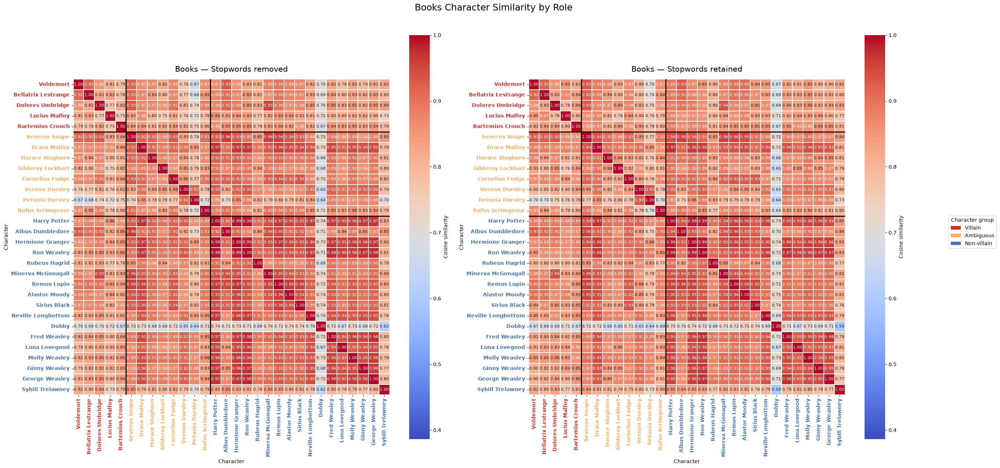

In [ ]:
plot_role_grouped_comparison(stopword_book_similarity_df, book_similarity_df, "Books")


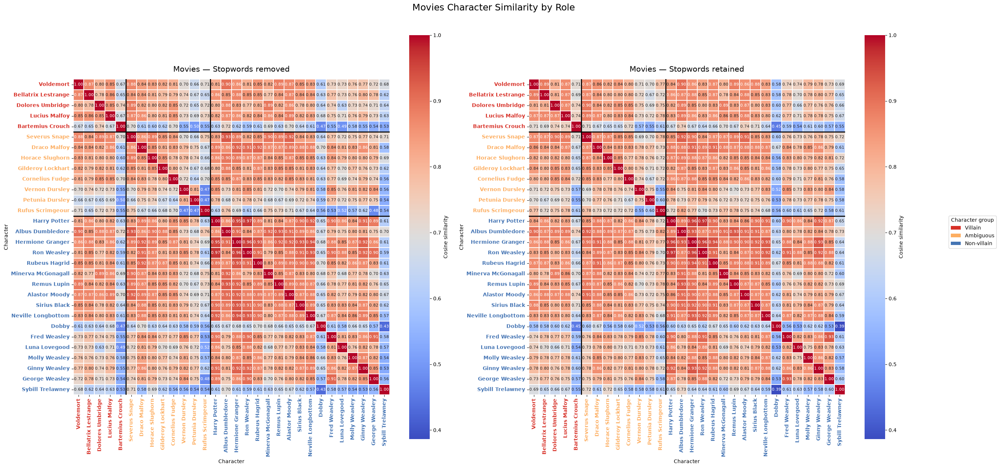

In [ ]:
plot_role_grouped_comparison(stopword_movie_similarity_df, movie_similarity_df, "Movies")


In [ ]:
for medium, cleaned, original in [
    ("Books", stopword_book_similarity_df, book_similarity_df),
    ("Movies", stopword_movie_similarity_df, movie_similarity_df),
]:
    delta = (cleaned - original).abs().to_numpy()
    print(
        medium,
        "mean absolute difference:", delta.mean(),
        "largest difference:", delta.max()
    )

Books mean absolute difference: 0.012876891728291139 largest difference: 0.06377885476870382
Movies mean absolute difference: 0.020407049612682575 largest difference: 0.12497074185536383


### t-SNE projection of BERT character embeddings

This projects the existing book and movie character embeddings into two dimensions. Distances in this plot are a visualization aid; t-SNE axes and global distances are not directly interpretable.

In [ ]:
# Project the same selected character embeddings used in the PaCMAP plots.
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

n = len(selected_characters)
X_tsne_input = np.vstack([book_X, movie_X])
X_tsne_input = normalize(X_tsne_input, norm="l2")

# t-SNE requires perplexity to be smaller than the number of samples.
tsne_perplexity = min(10, n - 1)
tsne = TSNE(
    n_components=2,
    perplexity=tsne_perplexity,
    init="pca",
    learning_rate="auto",
    metric="cosine",
    random_state=42
)
X_tsne = tsne.fit_transform(X_tsne_input)
print("t-SNE result shape:", X_tsne.shape)
print("Perplexity:", tsne_perplexity)

tsne_plot_df = pd.DataFrame({
    "character": selected_characters + selected_characters,
    "version": ["book"] * n + ["movie"] * n,
    "tSNE_1": X_tsne[:, 0],
    "tSNE_2": X_tsne[:, 1]
})

fig, ax = plt.subplots(figsize=(16, 12))
for version, marker, label in [("book", "o", "Books"), ("movie", "^", "Movies")]:
    subset = tsne_plot_df[tsne_plot_df["version"] == version]
    ax.scatter(subset["tSNE_1"], subset["tSNE_2"], marker=marker, s=100, alpha=0.8, label=label)

for _, row in tsne_plot_df.iterrows():
    offset = (5, 5) if row["version"] == "book" else (5, -8)
    ax.annotate(f"{row['character']} ({row['version'][0].upper()})",
                (row["tSNE_1"], row["tSNE_2"]), xytext=offset,
                textcoords="offset points", fontsize=8)

ax.set_title("Harry Potter Character Embeddings: Books vs Movies (t-SNE)", fontsize=16)
ax.set_xlabel("t-SNE Dimension 1")
ax.set_ylabel("t-SNE Dimension 2")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Testing embeddings

### Embeddings made with equal weight

This version gives each dialogue passage equal weight, regardless of token count. Long utterances split by the existing helper count as multiple passages.

In [94]:
# Re-embed each character/version using an unweighted mean of passage vectors.
from numpy.linalg import norm

bert_character_embeddings_equal = {}
character_chunk_counts_equal = {}

for key, dialogues in character_dialogues.items():
    passages = []
    for dialogue in dialogues:
        passages.extend(split_long_utterance(dialogue))

    if not passages:
        continue

    passage_embeddings = bert_model.encode(
        passages, batch_size=32, show_progress_bar=False,
        convert_to_numpy=True, normalize_embeddings=True
    )
    character_embedding = passage_embeddings.mean(axis=0)
    embedding_norm = norm(character_embedding)
    if embedding_norm > 0:
        character_embedding /= embedding_norm

    bert_character_embeddings_equal[key] = character_embedding
    character_chunk_counts_equal[key] = len(passages)

print("Number of equal-weight embeddings:", len(bert_character_embeddings_equal))
print("Embedding dimensions:", next(iter(bert_character_embeddings_equal.values())).shape)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (266 > 256). Running this sequence through the model will result in indexing errors


Number of equal-weight embeddings: 284
Embedding dimensions: (384,)


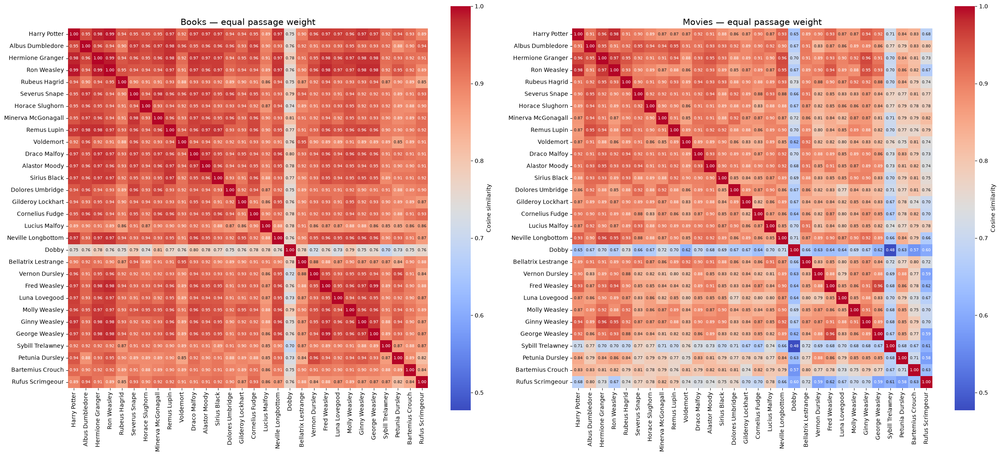

In [95]:
# Build paired book/movie vectors for the same selected characters.
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

equal_book_X = np.vstack([bert_character_embeddings_equal[("book", c)] for c in selected_characters])
equal_movie_X = np.vstack([bert_character_embeddings_equal[("movie", c)] for c in selected_characters])
equal_book_similarity = cosine_similarity(equal_book_X)
equal_movie_similarity = cosine_similarity(equal_movie_X)
equal_book_similarity_df = pd.DataFrame(equal_book_similarity, index=selected_characters, columns=selected_characters)
equal_movie_similarity_df = pd.DataFrame(equal_movie_similarity, index=selected_characters, columns=selected_characters)

# Order both matrices by the same role groups used in the earlier heatmaps.
ordered_equal_characters = villains + ambiguous + non_villains
assert set(ordered_equal_characters) == set(selected_characters)
equal_book_similarity_df = equal_book_similarity_df.loc[ordered_equal_characters, ordered_equal_characters]
equal_movie_similarity_df = equal_movie_similarity_df.loc[ordered_equal_characters, ordered_equal_characters]

role_sizes = [len(villains), len(ambiguous), len(non_villains)]
role_colors = {"Villain": "#d73027", "Ambiguous": "#fdae61", "Non-villain": "#4575b4"}
role_tick_colors = ([role_colors["Villain"]] * role_sizes[0]
                    + [role_colors["Ambiguous"]] * role_sizes[1]
                    + [role_colors["Non-villain"]] * role_sizes[2])

# Keep the color scale shared across books and movies for direct visual comparison.
similarity_min = min(equal_book_similarity.min(), equal_movie_similarity.min())
similarity_max = max(equal_book_similarity.max(), equal_movie_similarity.max())
fig, axes = plt.subplots(1, 2, figsize=(25, 11))
for ax, similarity_df, title in [(axes[0], equal_book_similarity_df, "Books — equal passage weight"), (axes[1], equal_movie_similarity_df, "Movies — equal passage weight")]:
    sns.heatmap(similarity_df, ax=ax, cmap="coolwarm", vmin=similarity_min, vmax=similarity_max, annot=True, fmt=".2f", annot_kws={"size":7}, square=True, linewidths=0.3, cbar_kws={"label":"Cosine similarity"})
    for tick_label, color in zip(ax.get_xticklabels(), role_tick_colors):
        tick_label.set_color(color)
        tick_label.set_fontweight("bold")
    for tick_label, color in zip(ax.get_yticklabels(), role_tick_colors):
        tick_label.set_color(color)
        tick_label.set_fontweight("bold")
    for boundary in (role_sizes[0], role_sizes[0] + role_sizes[1]):
        ax.axhline(boundary, color="black", linewidth=2)
        ax.axvline(boundary, color="black", linewidth=2)
    ax.set_title(title, fontsize=15)
    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)
fig.tight_layout()
plt.show()


Applied PCA, the dimensionality becomes 100
PaCMAP(n_neighbors=5, n_MN=2, n_FP=5, distance=euclidean, lr=1.0, n_iters=(100, 100, 250), apply_pca=True, opt_method='adam', verbose=True, intermediate=False, seed=42, knn_backend=annoy)
Finding pairs
Found nearest neighbor
Calculated sigma
Found scaled dist
Pairs sampled successfully.
((300, 2), (120, 2), (300, 2))
Initial Loss: 216.54405212402344
Iteration:   10, Loss: 182.868469
Iteration:   20, Loss: 168.738953
Iteration:   30, Loss: 162.299301
Iteration:   40, Loss: 157.868118
Iteration:   50, Loss: 153.757935
Iteration:   60, Loss: 149.707993
Iteration:   70, Loss: 145.419922
Iteration:   80, Loss: 140.716003
Iteration:   90, Loss: 135.385605
Iteration:  100, Loss: 129.031189
Iteration:  110, Loss: 168.340942
Iteration:  120, Loss: 167.993195
Iteration:  130, Loss: 167.930023
Iteration:  140, Loss: 167.864532
Iteration:  150, Loss: 167.858948
Iteration:  160, Loss: 167.851608
Iteration:  170, Loss: 167.850555
Iteration:  180, Loss: 167

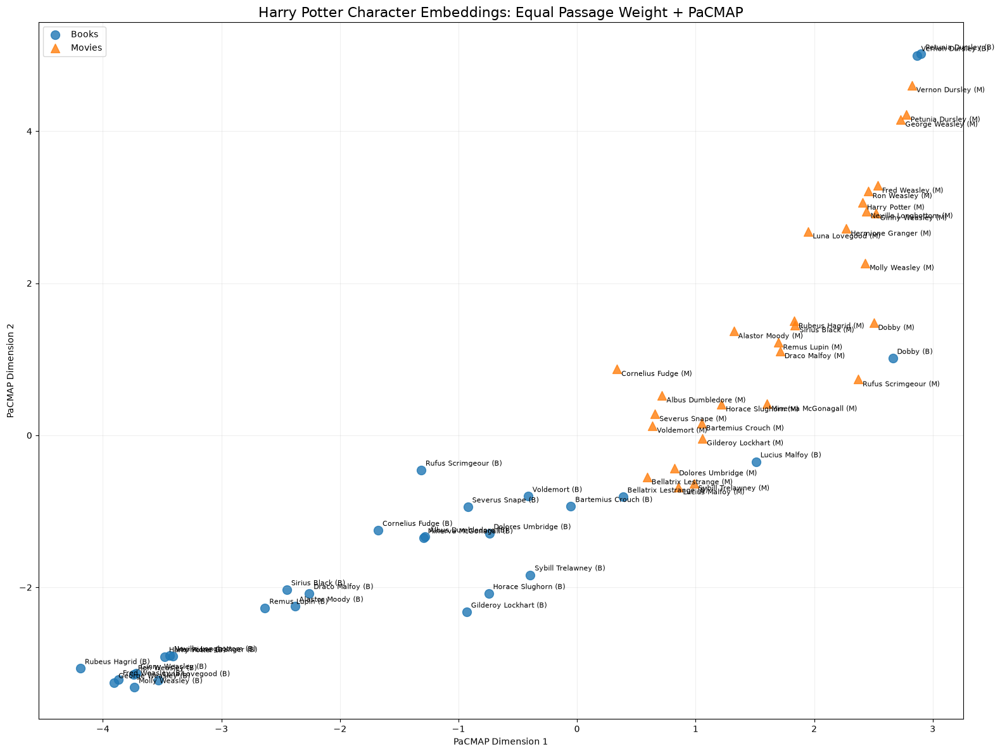

In [96]:
# Project equal-weight book and movie character vectors together with PaCMAP.
import pacmap
from sklearn.preprocessing import normalize

n = len(selected_characters)
equal_X_combined = np.vstack([equal_book_X, equal_movie_X])
equal_X_combined = normalize(equal_X_combined, norm="l2")
equal_X_combined = np.ascontiguousarray(equal_X_combined, dtype=np.float32)

equal_reducer = pacmap.PaCMAP(
    n_components=2, n_neighbors=5, MN_ratio=0.5, FP_ratio=1.0,
    knn_backend="annoy", verbose=True, random_state=42
)
X_pacmap_equal = equal_reducer.fit_transform(equal_X_combined, init="pca")
print("Equal-weight PaCMAP result shape:", X_pacmap_equal.shape)

equal_book_coordinates = X_pacmap_equal[:n]
equal_movie_coordinates = X_pacmap_equal[n:]
fig, ax = plt.subplots(figsize=(16, 12))
ax.scatter(equal_book_coordinates[:, 0], equal_book_coordinates[:, 1], marker="o", s=100, alpha=0.8, label="Books")
ax.scatter(equal_movie_coordinates[:, 0], equal_movie_coordinates[:, 1], marker="^", s=100, alpha=0.8, label="Movies")
for i, character in enumerate(selected_characters):
    ax.annotate(f"{character} (B)", equal_book_coordinates[i], xytext=(5, 5), textcoords="offset points", fontsize=8)
    ax.annotate(f"{character} (M)", equal_movie_coordinates[i], xytext=(5, -8), textcoords="offset points", fontsize=8)
ax.set_title("Harry Potter Character Embeddings: Equal Passage Weight + PaCMAP", fontsize=16)
ax.set_xlabel("PaCMAP Dimension 1")
ax.set_ylabel("PaCMAP Dimension 2")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()